# 数据与标注分析：ACRIMA 标注生物标志物的循环性

直接读取两个原始 parquet，从多个角度量化"标注生物标志物与诊断标签高度相关"这一问题，作为论文的动机与数据部分。不需要 GPU，一两分钟完成。

| 分析 | 回答的问题 |
|---|---|
| A. 数据集统计 | 样本量、类别比例、官方划分、原始图像尺寸 |
| B. 单个生物标志物的可分性 | 每个标注单独能否区分诊断（AUC、互信息、单阈值准确率） |
| C. 仅用标注的分类器 | 不看图像，只用标注能达到多高的性能 |
| D. 生物标志物相关性 | 标注之间、标注与标签之间的相关结构 |
| E. 文本泄漏 | 自由文本描述本身是否泄漏诊断 |
| F. 捷径特征 | 原始图像尺寸是否就能区分类别 |
| G. 近重复图像 | 官方 train/test 划分之间是否存在近重复 |

所有表格保存为 CSV 和 LaTeX（booktabs），图保存为 PDF 和 PNG，位于 `outputs_acrima/`。

In [1]:
# ═══════════════════════════════════════════════════════════
# Cell 1: 导入、路径、通用工具
# ═══════════════════════════════════════════════════════════
import io
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
DATA_DIR = Path("data")
FILES = {"train": "train-00000-of-00001.parquet", "test": "test-00000-of-00001.parquet"}
OUT = Path("outputs_acrima"); OUT.mkdir(exist_ok=True)
SEED = 42
C0, C1 = "#3498db", "#e74c3c"
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.bbox": "tight"})

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.pdf")
    fig.savefig(OUT / f"{name}.png", dpi=300)
    plt.show()

def to_booktabs(df, name, caption, label, index=True, float_fmt="{:.4f}"):
    """不依赖 jinja2 的 booktabs 表格导出，同时保存 CSV"""
    df.to_csv(OUT / f"{name}.csv", index=index)
    d = df.reset_index() if index else df.copy()
    fmt = lambda v: float_fmt.format(v) if isinstance(v, (float, np.floating)) and not np.isnan(v) else ("--" if isinstance(v, float) else str(v))
    esc = lambda s: str(s).replace("_", "\\_").replace("%", "\\%").replace("&", "\\&")
    lines = ["\\begin{table}[t]", "\\centering", f"\\caption{{{caption}}}", f"\\label{{{label}}}",
             "\\begin{tabular}{" + "l" + "c" * (d.shape[1] - 1) + "}", "\\toprule",
             " & ".join(esc(c) for c in d.columns) + " \\\\", "\\midrule"]
    lines += [" & ".join(esc(fmt(v)) for v in row) + " \\\\" for row in d.itertuples(index=False)]
    lines += ["\\bottomrule", "\\end{tabular}", "\\end{table}"]
    (OUT / f"{name}.tex").write_text("\n".join(lines))
    return df

In [2]:
# ═══════════════════════════════════════════════════════════
# Cell 2: 读取 parquet，解析标注，读取原始图像尺寸
# ═══════════════════════════════════════════════════════════
frames = []
for split, fn in FILES.items():
    d = pd.read_parquet(DATA_DIR / fn)
    d["split"] = split
    frames.append(d)
df = pd.concat(frames, ignore_index=True)

def to_bool(v):
    if isinstance(v, (bool, np.bool_)):
        return float(v)
    if isinstance(v, str) and v.strip().lower() in ("true", "false"):
        return float(v.strip().lower() == "true")
    return np.nan

def load_desc(raw):
    try:
        return json.loads(raw)
    except (TypeError, json.JSONDecodeError):
        return {}

DESC = df["description"].map(load_desc)
FF = DESC.map(lambda d: d.get("fundus_features", {}) or {})

def parse(ff):
    isnt = to_bool(ff.get("isnt_rule_followed"))
    return {"cdr": pd.to_numeric(ff.get("cup_to_disc_ratio"), errors="coerce"),
            "isnt_violated": np.nan if np.isnan(isnt) else 1.0 - isnt,
            "rim_thinning": to_bool(ff.get("rim_thinning")),
            "notching": to_bool(ff.get("notching")),
            "bayoneting": to_bool(ff.get("bayoneting")),
            "rim_pallor": to_bool(ff.get("rim_pallor")),
            "laminar_dot_sign": to_bool(ff.get("laminar_dot_sign"))}

bm = pd.DataFrame([parse(f) for f in FF])
BIN_COLS = [c for c in bm.columns if c != "cdr"]
y = (df["annotation"] == "glaucoma").astype(int).values
risk = DESC.map(lambda d: d.get("glaucoma_risk_assessment"))
conf = DESC.map(lambda d: pd.to_numeric(d.get("confidence_level"), errors="coerce"))

def img_bytes(v):
    return v["bytes"] if isinstance(v, dict) else v

sizes = [Image.open(io.BytesIO(img_bytes(v))).size for v in tqdm(df["image"], desc="读取尺寸")]
df["width"], df["height"] = [s[0] for s in sizes], [s[1] for s in sizes]
print(f"{len(df)} 张图像，青光眼 {y.sum()}，正常 {(1 - y).sum()}")
print("缺失值：", bm.isna().sum().to_dict())

读取尺寸:   0%|          | 0/689 [00:00<?, ?it/s]

689 张图像，青光眼 427，正常 262
缺失值： {'cdr': 0, 'isnt_violated': 0, 'rim_thinning': 0, 'notching': 0, 'bayoneting': 0, 'rim_pallor': 0, 'laminar_dot_sign': 0}


## A. 数据集统计

In [3]:
# ═══════════════════════════════════════════════════════════
# Cell 3: 数据集统计表
# ═══════════════════════════════════════════════════════════
rows = []
for split in ["train", "test", "all"]:
    m = np.ones(len(df), bool) if split == "all" else (df["split"] == split).values
    rows.append({"Split": split, "Images": int(m.sum()), "Glaucoma": int(y[m].sum()), "Normal": int((1 - y[m]).sum()),
                 "Glaucoma %": 100 * y[m].mean(),
                 "Width (median)": float(np.median(df.width[m])), "Height (median)": float(np.median(df.height[m]))})
stats = pd.DataFrame(rows).set_index("Split")
to_booktabs(stats, "table_dataset_stats", "ACRIMA dataset statistics.", "tab:dataset", float_fmt="{:.1f}")
stats

,Images,Glaucoma,Normal,Glaucoma %,Width (median),Height (median)
Split,,,,,,
train,589,375,214,63.667233,491.0,491.0
test,100,52,48,52.000000,418.5,418.5
all,689,427,262,61.973875,487.0,487.0


## B. 单个生物标志物的可分性

In [4]:
# ═══════════════════════════════════════════════════════════
# Cell 4: 单个生物标志物的 AUC、互信息、最优单阈值准确率
# ═══════════════════════════════════════════════════════════
def best_threshold_acc(v, y):
    """单个特征上的最优单阈值（决策树桩）准确率"""
    v = np.nan_to_num(v, nan=np.nanmedian(v))
    best = 0
    for t in np.unique(v):
        for pred in [(v >= t), (v < t)]:
            best = max(best, accuracy_score(y, pred.astype(int)))
    return best

X_fill = bm.fillna(bm.median())
mi = mutual_info_classif(X_fill.values, y, discrete_features=[c != "cdr" for c in bm.columns], random_state=SEED)
H_y = -sum(p * np.log(p) for p in [y.mean(), 1 - y.mean()])
rows = []
for k, c in enumerate(bm.columns):
    rows.append({"Biomarker": c, "AUC alone": roc_auc_score(y, X_fill[c]),
                 "Best single-threshold Acc": best_threshold_acc(bm[c].values, y),
                 "Mutual information (nats)": mi[k], "MI / H(Y)": mi[k] / H_y,
                 "Mean | glaucoma": bm[c][y == 1].mean(), "Mean | normal": bm[c][y == 0].mean()})
sep = pd.DataFrame(rows).set_index("Biomarker")
to_booktabs(sep, "table_annotation_separability", "Separability of each annotated biomarker with respect to the diagnosis.",
            "tab:separability")
sep.round(4)

,AUC alone,Best single-threshold Acc,Mutual information (nats),MI / H(Y),Mean | glaucoma,Mean | normal
Biomarker,,,,,,
cdr,1.0000,1.0000,0.6649,1.0011,0.7681,0.3792
isnt_violated,1.0000,1.0000,0.6642,1.0000,1.0000,0.0000
rim_thinning,1.0000,1.0000,0.6642,1.0000,1.0000,0.0000
notching,0.8642,0.8316,0.3259,0.4907,0.7283,0.0000
bayoneting,0.8642,0.8316,0.3259,0.4907,0.7283,0.0000
rim_pallor,0.8618,0.8287,0.3225,0.4856,0.7237,0.0000
laminar_dot_sign,0.7752,0.7213,0.2153,0.3242,0.5504,0.0000


In [5]:
# ═══════════════════════════════════════════════════════════
# Cell 5: CDR 取值与风险等级的交叉表
# ═══════════════════════════════════════════════════════════
cdr_tab = pd.crosstab(bm["cdr"], pd.Series(y).map({1: "glaucoma", 0: "normal"}).values)
cdr_tab.index.name = "CDR"
to_booktabs(cdr_tab, "table_cdr_by_class", "Annotated CDR values by class.", "tab:cdr", float_fmt="{:.0f}")
display(cdr_tab)
if risk.notna().any():
    risk_tab = pd.crosstab(risk, df["annotation"])
    risk_tab.index.name = "Risk level"
    to_booktabs(risk_tab, "table_risk_by_class", "Annotated risk level by diagnosis.", "tab:risk", float_fmt="{:.0f}")
    display(risk_tab)
if conf.notna().any():
    display(pd.crosstab(conf, df["annotation"]))

col_0,glaucoma,normal
CDR,,
0.30,0,55
0.35,0,2
0.40,0,203
0.45,0,1
0.50,0,1
0.60,1,0
0.70,138,0
0.80,284,0
0.90,4,0


annotation,glaucoma,normal
Risk level,,
healthy,0,7
high risk,381,0
moderate risk,46,0
very healthy,0,255


annotation,glaucoma,normal
description,,
0.80,39,0
0.85,7,0
0.90,379,38
0.95,2,199
0.98,0,1
1.00,0,24


## C. 仅用标注（不看图像）的分类器

In [6]:
# ═══════════════════════════════════════════════════════════
# Cell 6: 仅用标注生物标志物的 5 折交叉验证分类
#   若不看图像就能接近完美，说明基于这些标注的 KG 推理本质上是在复述标签
# ═══════════════════════════════════════════════════════════
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
w = {"cdr_high": 3, "cdr_mod": 2, "cdr_norm": -3, "rim_thinning": 3, "notching": 3, "isnt": 2,
     "bayoneting": 2, "rim_pallor": 1, "laminar_dot_sign": 1}
def rule_score(b):
    """与 04 中临床先验规则一致的硬阈值带符号分数"""
    c = b["cdr"].fillna(b["cdr"].median())
    b = b.fillna(0)
    return (w["cdr_high"] * (c >= 0.7) + w["cdr_mod"] * ((c >= 0.6) & (c < 0.7)) + w["cdr_norm"] * (c <= 0.5)
            + w["rim_thinning"] * b.rim_thinning + w["notching"] * b.notching
            + w["isnt"] * (2 * b.isnt_violated - 1) + w["bayoneting"] * b.bayoneting
            + w["rim_pallor"] * b.rim_pallor + w["laminar_dot_sign"] * b.laminar_dot_sign).values

models = {
    "Clinical-rule score (no training)": None,
    "CDR only (logistic)": (["cdr"], make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "All biomarkers (logistic)": (list(bm.columns), make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
    "All biomarkers (tree, depth 1)": (list(bm.columns), DecisionTreeClassifier(max_depth=1, random_state=SEED)),
    "All biomarkers (tree, depth 3)": (list(bm.columns), DecisionTreeClassifier(max_depth=3, random_state=SEED)),
    "Binary signs only (logistic)": (BIN_COLS, make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
}
rows = []
for name, spec in models.items():
    if spec is None:
        s = rule_score(bm)
        p = 1 / (1 + np.exp(-s / 1.5))
    else:
        cols, mdl = spec
        p = cross_val_predict(mdl, X_fill[cols].values, y, cv=skf, method="predict_proba")[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"Model (annotations only)": name, "AUC": roc_auc_score(y, p), "Acc": accuracy_score(y, pred),
                 "Balanced Acc": balanced_accuracy_score(y, pred), "F1": f1_score(y, pred),
                 "MCC": matthews_corrcoef(y, pred)})
ann_only = pd.DataFrame(rows).set_index("Model (annotations only)")
to_booktabs(ann_only, "table_annotation_only_classifiers",
            "Diagnosis from annotated biomarkers alone (no image input), 5-fold cross-validation.", "tab:annonly")
ann_only.round(4)

,AUC,Acc,Balanced Acc,F1,MCC
Model (annotations only),,,,,
Clinical-rule score (no training),1.0,1.0,1.0,1.0,1.0
CDR only (logistic),1.0,1.0,1.0,1.0,1.0
All biomarkers (logistic),1.0,1.0,1.0,1.0,1.0
"All biomarkers (tree, depth 1)",1.0,1.0,1.0,1.0,1.0
"All biomarkers (tree, depth 3)",1.0,1.0,1.0,1.0,1.0
Binary signs only (logistic),1.0,1.0,1.0,1.0,1.0


## D. 生物标志物相关性

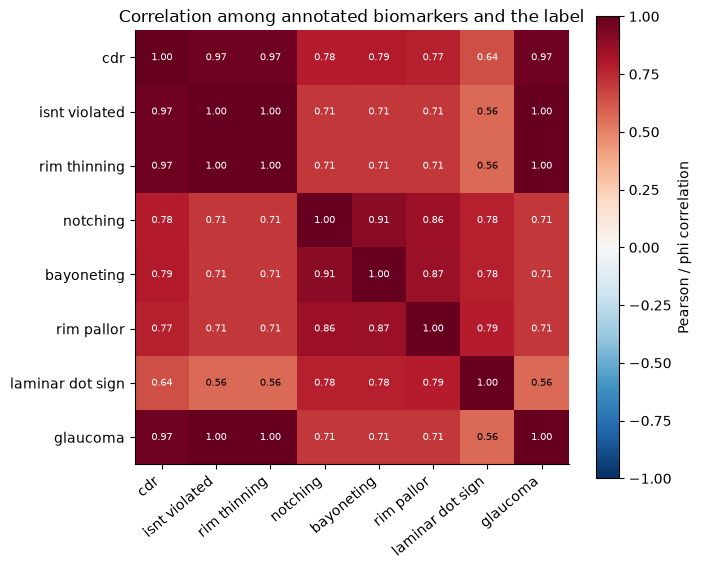

In [7]:
# ═══════════════════════════════════════════════════════════
# Cell 7: 生物标志物之间以及与标签的相关系数（二值变量即 phi 系数）
# ═══════════════════════════════════════════════════════════
corr = X_fill.assign(glaucoma=y).corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
for (i, j), v in np.ndenumerate(corr.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if abs(v) > 0.6 else "black")
labels = [c.replace("_", " ") for c in corr.columns]
ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=40, ha="right")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
fig.colorbar(im, ax=ax, label="Pearson / phi correlation")
ax.set_title("Correlation among annotated biomarkers and the label")
save_fig(fig, "fig0b_biomarker_correlation")

## E. 文本泄漏

,AUC,Acc,Balanced Acc,MCC
Text input,,,,
Full description JSON,1.0000,1.0000,1.0000,1.0000
Morphology free text only,0.9999,0.9956,0.9965,0.9908


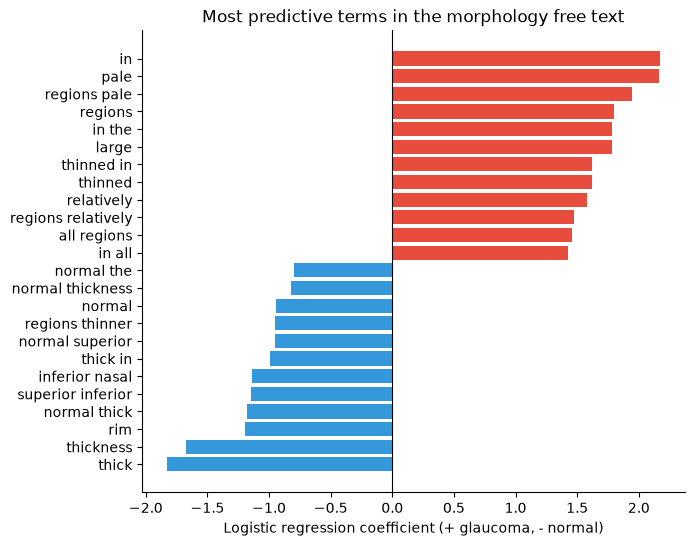

In [8]:
# ═══════════════════════════════════════════════════════════
# Cell 8: 仅用自由文本描述预测诊断（TF-IDF + 逻辑回归）
#   完整描述：包含风险等级等字段；仅形态描述：只保留 fundus_features 中的文字字段
# ═══════════════════════════════════════════════════════════
text_full = df["description"].fillna("").astype(str)
text_morph = FF.map(lambda f: " ".join(str(v) for v in f.values() if isinstance(v, str)))

rows, coefs = [], {}
for name, txt in [("Full description JSON", text_full), ("Morphology free text only", text_morph)]:
    if txt.str.strip().eq("").all():
        continue
    pipe = make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2), LogisticRegression(max_iter=2000, C=1.0))
    p = cross_val_predict(pipe, txt, y, cv=skf, method="predict_proba")[:, 1]
    pred = (p >= 0.5).astype(int)
    rows.append({"Text input": name, "AUC": roc_auc_score(y, p), "Acc": accuracy_score(y, pred),
                 "Balanced Acc": balanced_accuracy_score(y, pred), "MCC": matthews_corrcoef(y, pred)})
    pipe.fit(txt, y)
    vec, lr = pipe.named_steps["tfidfvectorizer"], pipe.named_steps["logisticregression"]
    coefs[name] = pd.Series(lr.coef_[0], index=vec.get_feature_names_out()).sort_values()
text_tab = pd.DataFrame(rows).set_index("Text input")
to_booktabs(text_tab, "table_text_leakage", "Diagnosis predicted from the free-text descriptions alone.", "tab:text")
display(text_tab.round(4))

if "Morphology free text only" in coefs:
    s = coefs["Morphology free text only"]
    top = pd.concat([s.head(12), s.tail(12)])
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(top.index, top.values, color=[C0 if v < 0 else C1 for v in top.values])
    ax.axvline(0, color="k", lw=0.8)
    ax.set(xlabel="Logistic regression coefficient (+ glaucoma, - normal)",
           title="Most predictive terms in the morphology free text")
    save_fig(fig, "fig0d_text_terms")

## F. 捷径特征：原始图像尺寸

,AUC alone,Median | glaucoma,Median | normal
Feature,,,
width,0.7869,691.0,363.0
height,0.7895,691.0,363.0
area,0.7897,477481.0,131770.0
aspect,0.5367,1.0,1.0


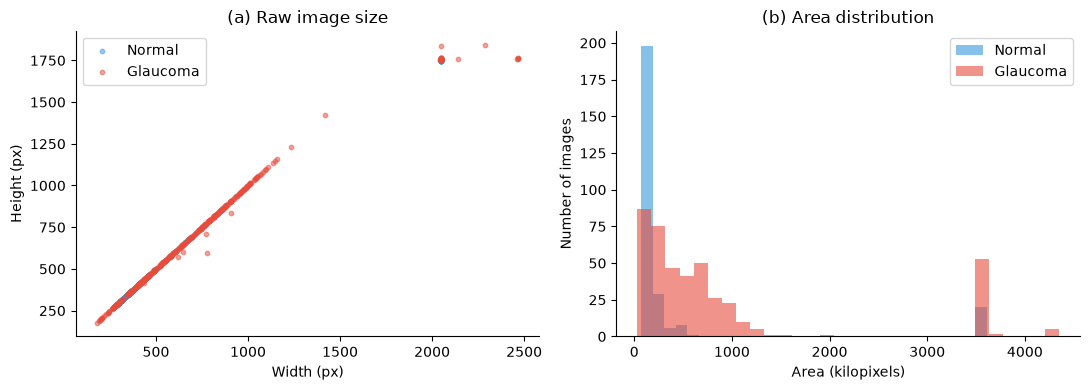

In [9]:
# ═══════════════════════════════════════════════════════════
# Cell 9: 原始图像尺寸能否区分类别
#   ACRIMA 为视盘裁剪图，尺寸若与类别相关，图像模型可能学到捷径
# ═══════════════════════════════════════════════════════════
size_feats = pd.DataFrame({"width": df.width, "height": df.height, "area": df.width * df.height,
                           "aspect": df.width / df.height})
rows = [{"Feature": c, "AUC alone": max(roc_auc_score(y, size_feats[c]), 1 - roc_auc_score(y, size_feats[c])),
         "Median | glaucoma": size_feats[c][y == 1].median(), "Median | normal": size_feats[c][y == 0].median()}
        for c in size_feats.columns]
size_tab = pd.DataFrame(rows).set_index("Feature")
to_booktabs(size_tab, "table_image_size_shortcut", "Separability of raw image size (potential shortcut).", "tab:size")
display(size_tab.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for lab, col, nm in [(0, C0, "Normal"), (1, C1, "Glaucoma")]:
    ax[0].scatter(df.width[y == lab], df.height[y == lab], s=10, alpha=0.5, color=col, label=nm)
    ax[1].hist(size_feats.area[y == lab] / 1e3, bins=30, alpha=0.6, color=col, label=nm)
ax[0].set(xlabel="Width (px)", ylabel="Height (px)", title="(a) Raw image size")
ax[1].set(xlabel="Area (kilopixels)", ylabel="Number of images", title="(b) Area distribution")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
save_fig(fig, "fig0c_image_size")

## G. 近重复图像

解码:   0%|          | 0/689 [00:00<?, ?it/s]

,Near-duplicate pairs (dist <= 4),Crossing train/test,Images involved,Pairs with different labels
0,39,7,77,0


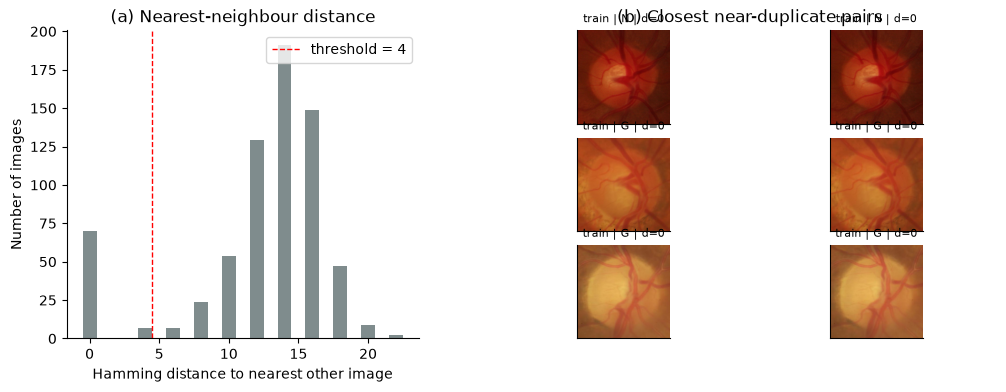

In [10]:
# ═══════════════════════════════════════════════════════════
# Cell 10: 近重复检测（感知哈希），尤其是跨越官方 train/test 划分的近重复
# ═══════════════════════════════════════════════════════════
import imagehash

PHASH_THR = 4
imgs = [Image.open(io.BytesIO(img_bytes(v))).convert("RGB") for v in tqdm(df["image"], desc="解码")]
hashes = np.array([imagehash.phash(im.convert("L").resize((256, 256))).hash.flatten() for im in imgs])
D = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)            # 汉明距离矩阵
np.fill_diagonal(D, 999)
nn_dist = D.min(1)
split = df["split"].values
iu = np.triu_indices(len(df), 1)
close = D[iu] <= PHASH_THR
pairs = pd.DataFrame({"i": iu[0][close], "j": iu[1][close], "dist": D[iu][close]})
pairs["cross_split"] = split[pairs.i] != split[pairs.j]
pairs["same_label"] = y[pairs.i] == y[pairs.j]
dup_tab = pd.DataFrame([{"Near-duplicate pairs (dist <= %d)" % PHASH_THR: len(pairs),
                         "Crossing train/test": int(pairs.cross_split.sum()),
                         "Images involved": len(set(pairs.i) | set(pairs.j)),
                         "Pairs with different labels": int((~pairs.same_label).sum())}])
to_booktabs(dup_tab, "table_near_duplicates", "Near-duplicate image pairs by perceptual hashing.", "tab:dup",
            index=False, float_fmt="{:.0f}")
display(dup_tab)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.4]})
ax[0].hist(nn_dist, bins=np.arange(0, nn_dist.max() + 2) - 0.5, color="#7f8c8d")
ax[0].axvline(PHASH_THR + 0.5, color="r", ls="--", lw=1, label=f"threshold = {PHASH_THR}")
ax[0].set(xlabel="Hamming distance to nearest other image", ylabel="Number of images", title="(a) Nearest-neighbour distance")
ax[0].legend()
ax[1].axis("off")
ex = pairs.sort_values("dist").head(3)
if len(ex):
    sub = ax[1].get_subplotspec().subgridspec(len(ex), 2, wspace=0.05, hspace=0.15)
    for r, (_, pr) in enumerate(ex.iterrows()):
        for c, k in enumerate([pr.i, pr.j]):
            a = fig.add_subplot(sub[r, c])
            a.imshow(imgs[k]); a.set_xticks([]); a.set_yticks([])
            a.set_title(f"{split[k]} | {'G' if y[k] else 'N'} | d={pr.dist}", fontsize=8)
    ax[1].set_title("(b) Closest near-duplicate pairs")
else:
    ax[1].text(0.5, 0.5, "No near-duplicate pairs found", ha="center", va="center")
save_fig(fig, "fig0e_near_duplicates")

## 汇总图

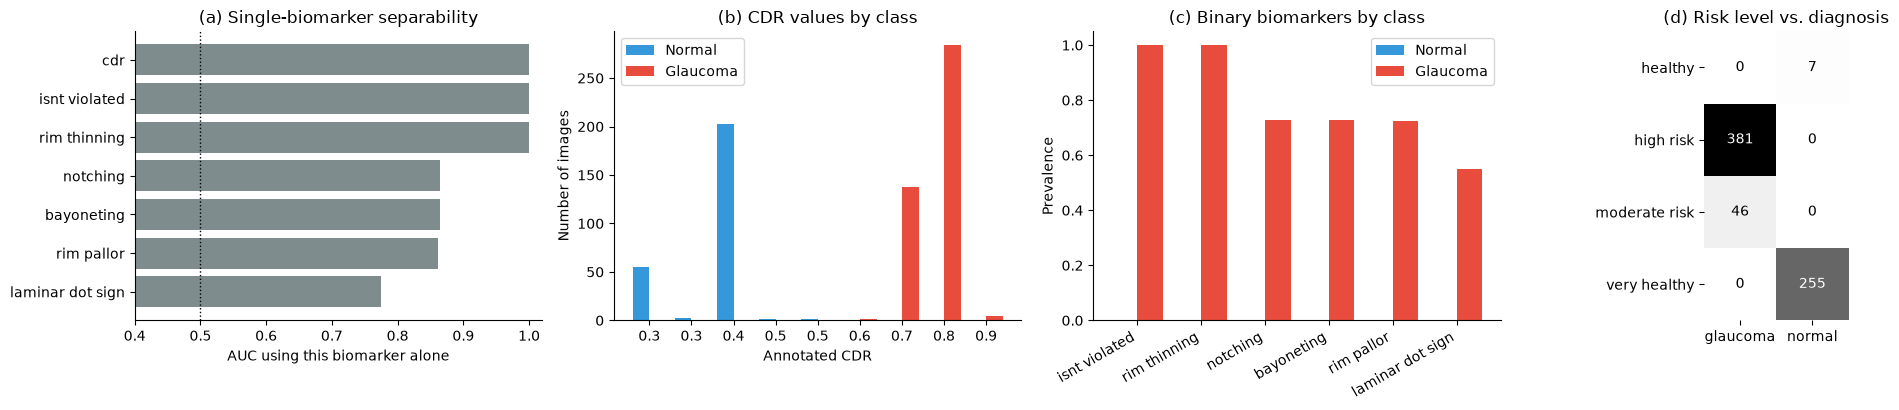

In [11]:
# ═══════════════════════════════════════════════════════════
# Cell 11: 动机汇总图（论文引言或数据部分使用）
#   (a) 单个生物标志物的 AUC  (b) CDR 取值按类别  (c) 二值征象出现率  (d) 风险等级与诊断
# ═══════════════════════════════════════════════════════════
has_risk = risk.notna().any()
fig, ax = plt.subplots(1, 4 if has_risk else 3, figsize=(20 if has_risk else 15, 4.2))
ax[0].barh([c.replace("_", " ") for c in sep.index], sep["AUC alone"], color="#7f8c8d")
ax[0].axvline(0.5, color="k", ls=":", lw=1)
ax[0].invert_yaxis()
ax[0].set(xlim=(0.4, 1.02), xlabel="AUC using this biomarker alone", title="(a) Single-biomarker separability")

cd = pd.crosstab(bm["cdr"], y)
x = np.arange(len(cd))
ax[1].bar(x - 0.2, cd.get(0, 0), 0.4, color=C0, label="Normal")
ax[1].bar(x + 0.2, cd.get(1, 0), 0.4, color=C1, label="Glaucoma")
ax[1].set_xticks(x); ax[1].set_xticklabels([f"{v:.1f}" for v in cd.index])
ax[1].set(xlabel="Annotated CDR", ylabel="Number of images", title="(b) CDR values by class")
ax[1].legend()

x = np.arange(len(BIN_COLS))
ax[2].bar(x - 0.2, [bm[c][y == 0].mean() for c in BIN_COLS], 0.4, color=C0, label="Normal")
ax[2].bar(x + 0.2, [bm[c][y == 1].mean() for c in BIN_COLS], 0.4, color=C1, label="Glaucoma")
ax[2].set_xticks(x); ax[2].set_xticklabels([c.replace("_", " ") for c in BIN_COLS], rotation=30, ha="right")
ax[2].set(ylim=(0, 1.05), ylabel="Prevalence", title="(c) Binary biomarkers by class")
ax[2].legend()

if has_risk:
    rt = pd.crosstab(risk, df["annotation"])
    ax[3].imshow(rt.values, cmap="Greys")
    for (i, j), v in np.ndenumerate(rt.values):
        ax[3].text(j, i, v, ha="center", va="center", color="white" if v > rt.values.max() / 2 else "black")
    ax[3].set_xticks(range(rt.shape[1])); ax[3].set_xticklabels(rt.columns)
    ax[3].set_yticks(range(rt.shape[0])); ax[3].set_yticklabels(rt.index)
    ax[3].set(title="(d) Risk level vs. diagnosis")
    ax[3].spines[:].set_visible(False)
plt.tight_layout()
save_fig(fig, "fig0_annotation_circularity")